In [1]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 

Total dataset count: 460328
Relaxed: 460328 
Bin 1: 975193 
Bin 2: 762887 
Bin 3: 448541 
Bin 4: 446846 
Total: 2633467


(array([1.1000e+01, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        1.1014e+04, 9.8790e+03, 7.6950e+03, 7.7300e+03, 7.9130e+03,
        8.4450e+03, 9.4150e+03, 9.8160e+03, 1.0035e+04, 1.0364e+04,
        1.0422e+04, 1.0680e+04, 1.0782e+04, 1.0670e+04, 1.0717e+04,
        1.0646e+04, 1.0574e+04, 1.0406e+04, 1.0395e+04, 1.0347e+04,
        1.0141e+04, 9.9740e+03, 9.7430e+03, 9.6480e+03, 9.3810e+03,
        9.2390e+03, 9.1350e+03, 8.8190e+03, 8.8140e+03, 8.3250e+03,
        8.3970e+03, 8.2270e+03, 7.9830e+03, 8.0500e+03, 7.8980e+03,
        7.7100e+03, 7.4380e+03, 7.2870e+03, 7.2420e+03, 7.2110e+03,
        7.0180e+03, 6.9750e+03, 6.7370e+03, 6.6630e+03, 6.5560e+03,
        6.3080e+03, 6.3910e+03, 6.2690e+03, 5.9580e+03, 5.9560e+03,
        5.8170e+03, 5.9510e+03, 5.7430e+03, 5.7600e+03]),
 array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
        0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
        0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.

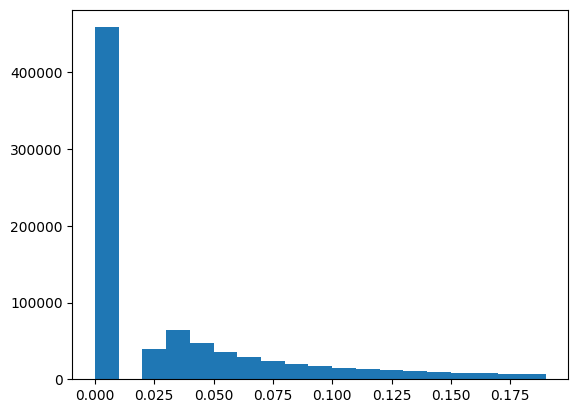

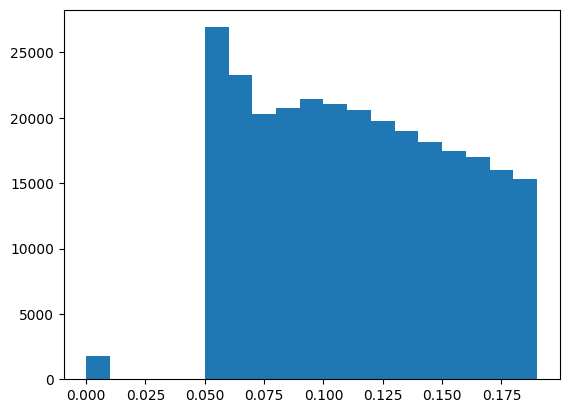

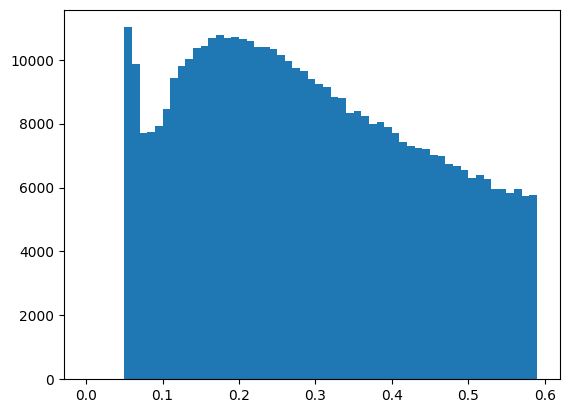

In [4]:
# Read the selected_frames.parquet file
df = pd.read_parquet('selected_frames.parquet')

# Get total count
total_count = len(df)
print(f"Total dataset count: {total_count}")

# Collect dE, Fmax, dS values
dE_values = df['dE'].to_numpy()
Fmax_values = df['Fmax'].to_numpy()
dSmax_values = df['dSmax'].to_numpy()

dE = np.concatenate(dE_values)
Fmax = np.concatenate(Fmax_values)
dSmax = np.concatenate(dSmax_values)

relaxed_count = (dSmax == 0).sum()

bin1_count = ((Fmax < 0.05)).sum()
bin2_count = ((Fmax >= 0.05) & (Fmax < 0.10)).sum()
bin3_count = ((Fmax >= 0.10) & (Fmax < 0.30)).sum()
bin4_count = ((Fmax >= 0.30) & (Fmax < 0.60)).sum()
total = bin1_count + bin2_count + bin3_count + bin4_count
print(f"Relaxed: {relaxed_count} \nBin 1: {bin1_count} \nBin 2: {bin2_count} \nBin 3: {bin3_count} \nBin 4: {bin4_count} \nTotal: {len(dSmax)}")

plt.figure()
bin1_dist = dSmax[Fmax < 0.05]
bins = np.arange(0, 0.20, 0.01)
plt.hist(bin1_dist, bins=bins)

plt.figure()
bin2_dist = dSmax[(Fmax >= 0.05) & (Fmax < 0.10)]
bins = np.arange(0, 0.20, 0.01)
plt.hist(bin2_dist, bins=bins)


plt.figure()
bin3_dist = dSmax[(Fmax >= 0.10) & (Fmax < 0.60)]
bins = np.arange(0, 0.60, 0.01)
plt.hist(bin3_dist, bins=bins)

In [6]:
# Collect dE, Fmax, dS values
dE_values = df['dE'].to_numpy()
Fmax_values = df['Fmax'].to_numpy()
dSmax_values = df['dSmax'].to_numpy()

count = 0 
count2 = 0
for idx in range(0, len(dSmax_values)):
    s = dSmax_values[idx]    
    diff = abs(s[:, None] - s[None, :])
    
    mask = ~np.eye(diff.shape[0], dtype=bool)
    
    hits = (diff < 0.025) & (diff != 0)
    hits = np.unique(hits)

    if hits.any():
        count += hits.sum()
        count2 += 1 if np.argmin(dSmax_values[idx]) != 0 else 0 
        
       
   
print(count, count2)

0 0
